In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/weather_data.csv")

df.head()

,time,temperature_2m,relative_humidity_2m,pressure_msl,wind_speed_10m,wind_direction_10m
0,2026-03-01T00:00,25.6,86,1008.8,8.7,339
1,2026-03-01T01:00,25.2,87,1008.4,6.4,331
2,2026-03-01T02:00,24.7,88,1007.7,6.5,328
3,2026-03-01T03:00,24.1,91,1007.7,6.1,346
4,2026-03-01T04:00,23.3,94,1007.8,3.3,347


In [3]:
df.shape

(4416, 6)

In [4]:
df.isnull().sum()

time                    0
temperature_2m          0
relative_humidity_2m    0
pressure_msl            0
wind_speed_10m          0
wind_direction_10m      0
dtype: int64

In [5]:
df["wind_speed_10m"].describe()

count    4416.000000
mean        7.429348
std         4.712473
min         0.000000
25%         3.500000
50%         6.500000
75%        10.700000
max        22.900000
Name: wind_speed_10m, dtype: float64

In [6]:
df["time"] = pd.to_datetime(df["time"])
df["hour"] = df["time"].dt.hour

df.head()

,time,temperature_2m,relative_humidity_2m,pressure_msl,wind_speed_10m,wind_direction_10m,hour
0,2026-03-01 00:00:00,25.6,86,1008.8,8.7,339,0
1,2026-03-01 01:00:00,25.2,87,1008.4,6.4,331,1
2,2026-03-01 02:00:00,24.7,88,1007.7,6.5,328,2
3,2026-03-01 03:00:00,24.1,91,1007.7,6.1,346,3
4,2026-03-01 04:00:00,23.3,94,1007.8,3.3,347,4


In [7]:
hourly_wind = df.groupby("hour")["wind_speed_10m"].mean()

hourly_wind

hour
0      5.320109
1      5.017391
2      4.682065
3      4.261413
4      4.460870
5      5.397826
6      4.942391
7      4.955435
8      4.777717
9      5.221196
10     6.854348
11     8.897826
12    11.591848
13    12.843478
14    13.285870
15    13.134783
16    12.550543
17    10.632609
18     8.885870
19     7.584239
20     6.453261
21     5.419565
22     5.345109
23     5.788587
Name: wind_speed_10m, dtype: float64

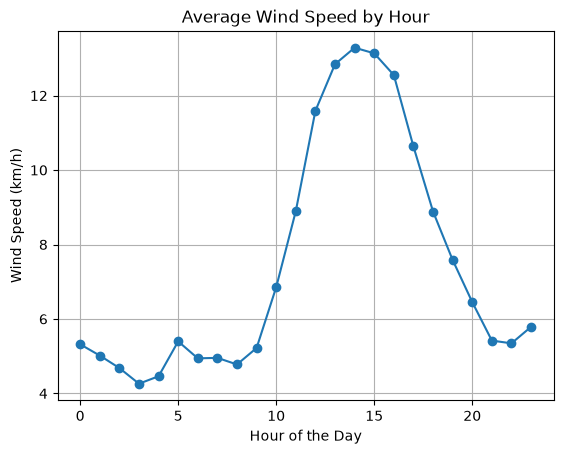

In [8]:
hourly_wind.plot(
    kind="line",
    marker="o",
    title="Average Wind Speed by Hour"
)

plt.xlabel("Hour of the Day")
plt.ylabel("Wind Speed (km/h)")
plt.grid()
plt.show()

In [9]:
print("Strongest wind hour:", hourly_wind.idxmax())
print("Weakest wind hour:", hourly_wind.idxmin())

Strongest wind hour: 14
Weakest wind hour: 3


In [10]:
df[["temperature_2m", "wind_speed_10m"]].corr()

,temperature_2m,wind_speed_10m
temperature_2m,1.000000,0.524693
wind_speed_10m,0.524693,1.000000


In [11]:
df[["relative_humidity_2m", "wind_speed_10m"]].corr()

,relative_humidity_2m,wind_speed_10m
relative_humidity_2m,1.000000,-0.545397
wind_speed_10m,-0.545397,1.000000


In [12]:
df[["pressure_msl", "wind_speed_10m"]].corr()

,pressure_msl,wind_speed_10m
pressure_msl,1.000000,-0.259118
wind_speed_10m,-0.259118,1.000000


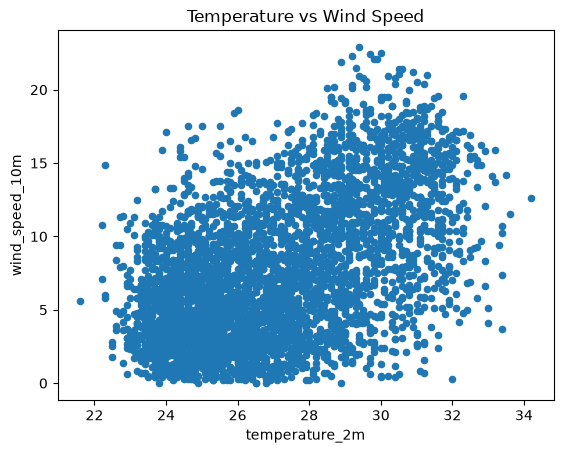

In [13]:
df.plot(
    kind="scatter",
    x="temperature_2m",
    y="wind_speed_10m",
    title="Temperature vs Wind Speed"
)

plt.show()

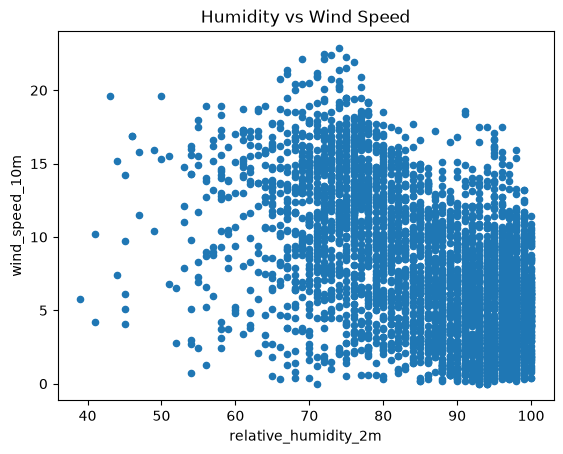

In [14]:
df.plot(
    kind="scatter",
    x="relative_humidity_2m",
    y="wind_speed_10m",
    title="Humidity vs Wind Speed"
)

plt.show()

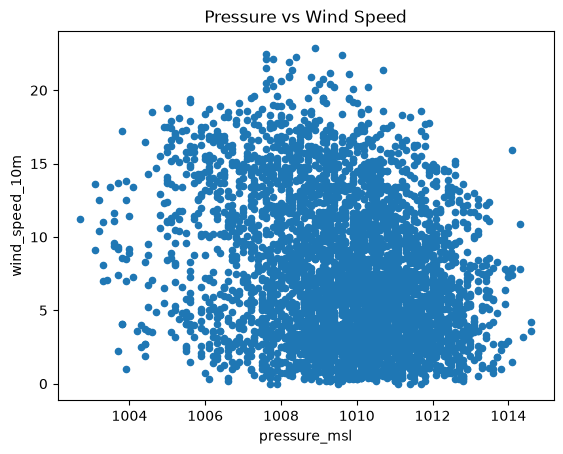

In [15]:
df.plot(
    kind="scatter",
    x="pressure_msl",
    y="wind_speed_10m",
    title="Pressure vs Wind Speed"
)

plt.show()

In [16]:
df["wind_direction_10m"].describe()

count    4416.000000
mean      240.728034
std        94.881819
min         1.000000
25%       187.000000
50%       274.000000
75%       310.000000
max       360.000000
Name: wind_direction_10m, dtype: float64

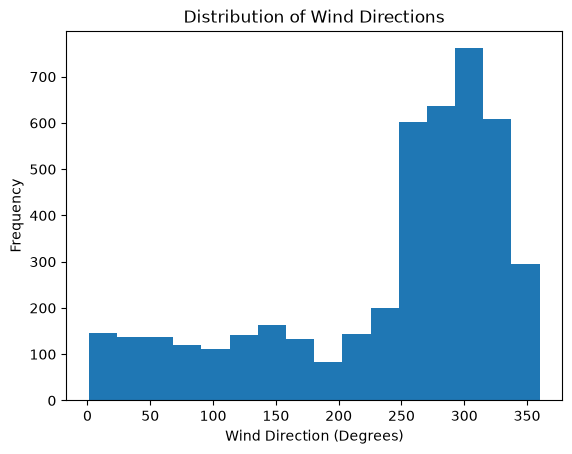

In [17]:
df["wind_direction_10m"].plot(
    kind="hist",
    bins=16,
    title="Distribution of Wind Directions"
)

plt.xlabel("Wind Direction (Degrees)")
plt.ylabel("Frequency")
plt.show()

In [18]:
bins = [0, 45, 90, 135, 180, 225, 270, 315, 360]

labels = [
    "N", "NE", "E", "SE",
    "S", "SW", "W", "NW"
]

df["direction_group"] = pd.cut(
    df["wind_direction_10m"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

df["direction_group"].value_counts()

direction_group
W     1397
NW     904
SW     802
SE     296
N      282
NE     256
E      252
S      227
Name: count, dtype: int64

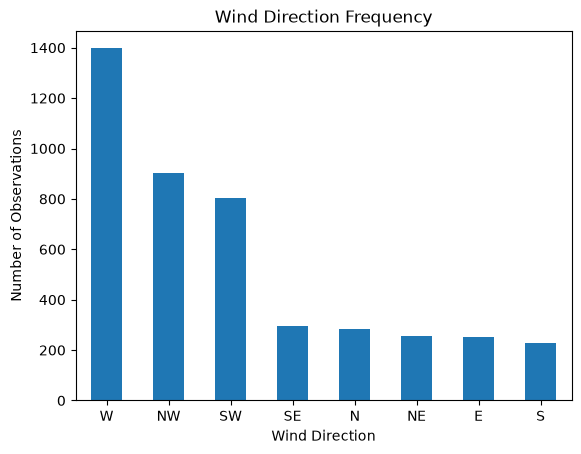

In [19]:
df["direction_group"].value_counts().plot(
    kind="bar",
    title="Wind Direction Frequency"
)

plt.xlabel("Wind Direction")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.show()

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4416 entries, 0 to 4415
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  4416 non-null   datetime64[us]
 1   temperature_2m        4416 non-null   float64       
 2   relative_humidity_2m  4416 non-null   int64         
 3   pressure_msl          4416 non-null   float64       
 4   wind_speed_10m        4416 non-null   float64       
 5   wind_direction_10m    4416 non-null   int64         
 6   hour                  4416 non-null   int32         
 7   direction_group       4416 non-null   category      
dtypes: category(1), datetime64[us](1), float64(3), int32(1), int64(2)
memory usage: 229.1 KB


In [21]:
df["time"] = pd.to_datetime(df["time"])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4416 entries, 0 to 4415
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  4416 non-null   datetime64[us]
 1   temperature_2m        4416 non-null   float64       
 2   relative_humidity_2m  4416 non-null   int64         
 3   pressure_msl          4416 non-null   float64       
 4   wind_speed_10m        4416 non-null   float64       
 5   wind_direction_10m    4416 non-null   int64         
 6   hour                  4416 non-null   int32         
 7   direction_group       4416 non-null   category      
dtypes: category(1), datetime64[us](1), float64(3), int32(1), int64(2)
memory usage: 229.1 KB


In [22]:
df["hour"] = df["time"].dt.hour
df["day"] = df["time"].dt.day
df["month"] = df["time"].dt.month
df["day_of_week"] = df["time"].dt.dayofweek

df.head()

,time,temperature_2m,relative_humidity_2m,pressure_msl,wind_speed_10m,wind_direction_10m,hour,direction_group,day,month,day_of_week
0,2026-03-01 00:00:00,25.6,86,1008.8,8.7,339,0,NW,1,3,6
1,2026-03-01 01:00:00,25.2,87,1008.4,6.4,331,1,NW,1,3,6
2,2026-03-01 02:00:00,24.7,88,1007.7,6.5,328,2,NW,1,3,6
3,2026-03-01 03:00:00,24.1,91,1007.7,6.1,346,3,NW,1,3,6
4,2026-03-01 04:00:00,23.3,94,1007.8,3.3,347,4,NW,1,3,6


In [23]:
monthly_wind = df.groupby("month")["wind_speed_10m"].mean()

monthly_wind

month
3    7.698790
4    8.241389
5    6.903360
6    6.685139
7    7.001613
8    8.047984
Name: wind_speed_10m, dtype: float64

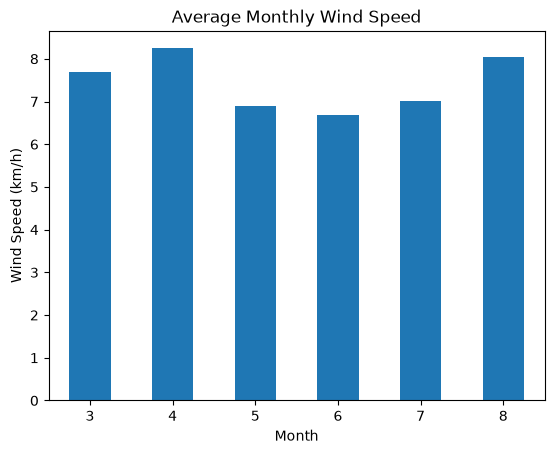

In [24]:
monthly_wind.plot(
    kind="bar",
    title="Average Monthly Wind Speed"
)

plt.xlabel("Month")
plt.ylabel("Wind Speed (km/h)")
plt.xticks(rotation=0)
plt.show()

In [25]:
daily_wind = df.groupby("day")["wind_speed_10m"].mean()

daily_wind

day
1     7.284722
2     7.045833
3     7.730556
4     6.925694
5     7.256250
6     7.859028
7     8.575000
8     7.333333
9     6.972222
10    7.372917
11    8.497917
12    8.418750
13    7.809028
14    8.454861
15    8.793056
16    9.027778
17    6.773611
18    7.038194
19    8.025000
20    7.097222
21    7.229861
22    6.534028
23    7.234028
24    6.862500
25    6.236111
26    6.136806
27    6.786111
28    7.058333
29    7.793750
30    6.571528
31    7.648958
Name: wind_speed_10m, dtype: float64

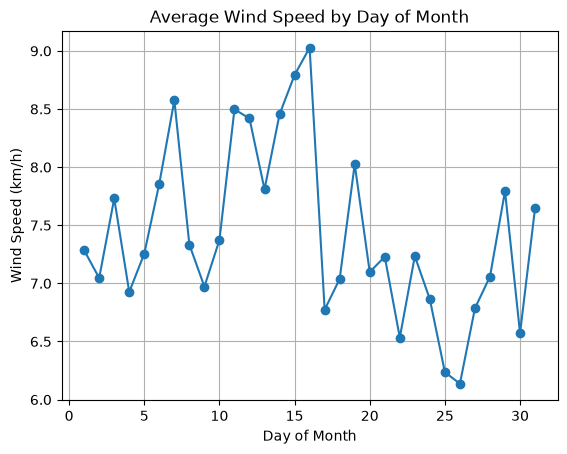

In [26]:
daily_wind.plot(
    kind="line",
    marker="o",
    title="Average Wind Speed by Day of Month"
)

plt.xlabel("Day of Month")
plt.ylabel("Wind Speed (km/h)")
plt.grid()
plt.show()

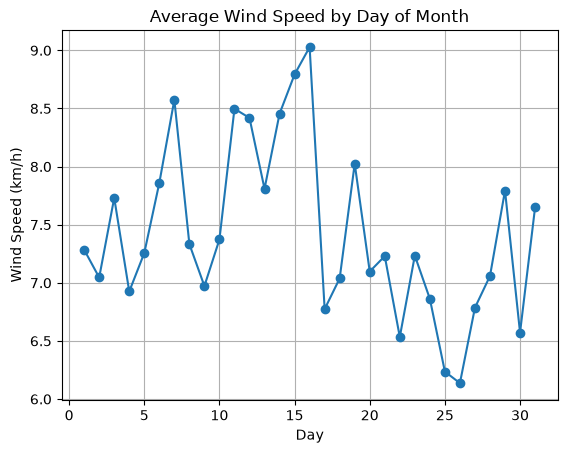

In [27]:
daily_wind.plot(
    kind="line",
    marker="o",
    title="Average Wind Speed by Day of Month"
)

plt.xlabel("Day")
plt.ylabel("Wind Speed (km/h)")
plt.grid()
plt.show()

In [28]:
df[["time", "wind_speed_10m"]].head(10)

,time,wind_speed_10m
0,2026-03-01 00:00:00,8.7
1,2026-03-01 01:00:00,6.4
2,2026-03-01 02:00:00,6.5
3,2026-03-01 03:00:00,6.1
4,2026-03-01 04:00:00,3.3
5,2026-03-01 05:00:00,4.1
6,2026-03-01 06:00:00,2.8
7,2026-03-01 07:00:00,4.6
8,2026-03-01 08:00:00,3.4
9,2026-03-01 09:00:00,2.0


In [29]:
df["previous_hour_wind"] = df["wind_speed_10m"].shift(1)

df[["time", "wind_speed_10m", "previous_hour_wind"]].head(10)

,time,wind_speed_10m,previous_hour_wind
0,2026-03-01 00:00:00,8.7,NaN
1,2026-03-01 01:00:00,6.4,8.7
2,2026-03-01 02:00:00,6.5,6.4
3,2026-03-01 03:00:00,6.1,6.5
4,2026-03-01 04:00:00,3.3,6.1
5,2026-03-01 05:00:00,4.1,3.3
6,2026-03-01 06:00:00,2.8,4.1
7,2026-03-01 07:00:00,4.6,2.8
8,2026-03-01 08:00:00,3.4,4.6
9,2026-03-01 09:00:00,2.0,3.4


In [30]:
df["wind_2_hours_ago"] = df["wind_speed_10m"].shift(2)

df["wind_3_hours_ago"] = df["wind_speed_10m"].shift(3)

df[[
    "time",
    "wind_speed_10m",
    "previous_hour_wind",
    "wind_2_hours_ago",
    "wind_3_hours_ago"
]].head(10)

,time,wind_speed_10m,previous_hour_wind,wind_2_hours_ago,wind_3_hours_ago
0,2026-03-01 00:00:00,8.7,NaN,NaN,NaN
1,2026-03-01 01:00:00,6.4,8.7,NaN,NaN
2,2026-03-01 02:00:00,6.5,6.4,8.7,NaN
3,2026-03-01 03:00:00,6.1,6.5,6.4,8.7
4,2026-03-01 04:00:00,3.3,6.1,6.5,6.4
5,2026-03-01 05:00:00,4.1,3.3,6.1,6.5
6,2026-03-01 06:00:00,2.8,4.1,3.3,6.1
7,2026-03-01 07:00:00,4.6,2.8,4.1,3.3
8,2026-03-01 08:00:00,3.4,4.6,2.8,4.1
9,2026-03-01 09:00:00,2.0,3.4,4.6,2.8


In [31]:
df = df.dropna()

df.head()

,time,temperature_2m,relative_humidity_2m,pressure_msl,wind_speed_10m,wind_direction_10m,hour,direction_group,day,month,day_of_week,previous_hour_wind,wind_2_hours_ago,wind_3_hours_ago
3,2026-03-01 03:00:00,24.1,91,1007.7,6.1,346,3,NW,1,3,6,6.5,6.4,8.7
4,2026-03-01 04:00:00,23.3,94,1007.8,3.3,347,4,NW,1,3,6,6.1,6.5,6.4
5,2026-03-01 05:00:00,23.2,93,1008.1,4.1,337,5,NW,1,3,6,3.3,6.1,6.5
6,2026-03-01 06:00:00,23.1,94,1009.0,2.8,35,6,N,1,3,6,4.1,3.3,6.1
7,2026-03-01 07:00:00,23.5,94,1009.9,4.6,126,7,E,1,3,6,2.8,4.1,3.3


In [32]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (4413, 14)

Missing values:
time                    0
temperature_2m          0
relative_humidity_2m    0
pressure_msl            0
wind_speed_10m          0
wind_direction_10m      0
hour                    0
direction_group         0
day                     0
month                   0
day_of_week             0
previous_hour_wind      0
wind_2_hours_ago        0
wind_3_hours_ago        0
dtype: int64


In [33]:
features = [
    "temperature_2m",
    "relative_humidity_2m",
    "pressure_msl",
    "hour",
    "month",
    "previous_hour_wind",
    "wind_2_hours_ago",
    "wind_3_hours_ago"
]

X = df[features]

y = df["wind_speed_10m"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (4413, 8)
Target shape: (4413,)


In [34]:
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 3530
Testing records: 883


In [35]:
# Create a target containing the next hour's wind speed
df["target_next_hour"] = df["wind_speed_10m"].shift(-1)

# Remove the final row because it has no next-hour value
df = df.dropna(subset=["target_next_hour"])

# Select input features
features = [
    "temperature_2m",
    "relative_humidity_2m",
    "pressure_msl",
    "hour",
    "month",
    "wind_speed_10m",
    "previous_hour_wind",
    "wind_2_hours_ago",
    "wind_3_hours_ago"
]

X = df[features]
y = df["target_next_hour"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (4412, 9)
Target shape: (4412,)


In [36]:
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 3529
Testing records: 883


In [37]:
from sklearn.ensemble import RandomForestRegressor

# Create the model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [38]:
predictions = model.predict(X_test)

print("First 10 predicted wind speeds:")
print(predictions[:10])

print("\nFirst 10 actual wind speeds:")
print(y_test.iloc[:10].values)

First 10 predicted wind speeds:
[ 3.993  7.632  5.116  5.239  4.365  3.731  5.764  5.679 10.952 11.968]

First 10 actual wind speeds:
[ 7.7  5.6  4.8  4.3  2.3  4.1  2.   9.8 13.2 13. ]


In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("Mean Absolute Error:", round(mae, 2), "km/h")
print("Root Mean Squared Error:", round(rmse, 2), "km/h")

Mean Absolute Error: 2.1 km/h
Root Mean Squared Error: 2.72 km/h


In [40]:
import pandas as pd

evaluation = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": predictions
})

evaluation["Error"] = abs(
    evaluation["Actual"] - evaluation["Predicted"]
)

evaluation.head(10)

,Actual,Predicted,Error
0,7.7,3.993,3.707
1,5.6,7.632,2.032
2,4.8,5.116,0.316
3,4.3,5.239,0.939
4,2.3,4.365,2.065
5,4.1,3.731,0.369
6,2.0,5.764,3.764
7,9.8,5.679,4.121
8,13.2,10.952,2.248
9,13.0,11.968,1.032


In [41]:
evaluation.sort_values(
    by="Error",
    ascending=False
).head(10)

,Actual,Predicted,Error
833,15.9,3.497,12.403
288,15.8,4.262,11.538
138,13.7,2.761,10.939
146,15.4,5.329,10.071
80,16.3,6.271,10.029
152,15.0,6.712,8.288
72,12.5,4.340,8.160
130,13.7,5.610,8.090
299,13.8,5.799,8.001
205,17.1,9.312,7.788


In [42]:
# Predict that the next hour's wind speed
# will be the same as the current hour's wind speed.

baseline_predictions = X_test["wind_speed_10m"]

baseline_mae = mean_absolute_error(y_test, baseline_predictions)

print("Baseline MAE:", round(baseline_mae, 2), "km/h")
print("Random Forest MAE:", round(mae, 2), "km/h")

Baseline MAE: 2.38 km/h
Random Forest MAE: 2.1 km/h


In [43]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

                Feature  Importance
5        wind_speed_10m    0.718396
0        temperature_2m    0.060366
1  relative_humidity_2m    0.050742
3                  hour    0.036128
6    previous_hour_wind    0.034469
2          pressure_msl    0.030364
7      wind_2_hours_ago    0.029728
8      wind_3_hours_ago    0.028540
4                 month    0.011266


In [44]:
features = [
    "temperature_2m",
    "relative_humidity_2m",
    "pressure_msl",
    "hour",
    "month",
    "wind_speed_10m",
    "previous_hour_wind",
    "wind_2_hours_ago",
    "wind_3_hours_ago"
]

In [45]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

In [46]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained again!")

Model trained again!


In [47]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load the dataset
df = pd.read_csv("../data/weather_data.csv")

# Convert time column
df["time"] = pd.to_datetime(df["time"])

# Create time features
df["hour"] = df["time"].dt.hour
df["month"] = df["time"].dt.month

# Create previous wind speed features
df["previous_hour_wind"] = df["wind_speed_10m"].shift(1)
df["wind_2_hours_ago"] = df["wind_speed_10m"].shift(2)
df["wind_3_hours_ago"] = df["wind_speed_10m"].shift(3)

# Create next-hour prediction target
df["target_next_hour"] = df["wind_speed_10m"].shift(-1)

# Remove missing rows
df = df.dropna()

# Select features
features = [
    "temperature_2m",
    "relative_humidity_2m",
    "pressure_msl",
    "hour",
    "month",
    "wind_speed_10m",
    "previous_hour_wind",
    "wind_2_hours_ago",
    "wind_3_hours_ago"
]

X = df[features]
y = df["target_next_hour"]

# Split data chronologically
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train the model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Model trained successfully!
Training rows: 3529
Testing rows: 883


In [48]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

                Feature  Importance
5        wind_speed_10m    0.718396
0        temperature_2m    0.060366
1  relative_humidity_2m    0.050742
3                  hour    0.036128
6    previous_hour_wind    0.034469
2          pressure_msl    0.030364
7      wind_2_hours_ago    0.029728
8      wind_3_hours_ago    0.028540
4                 month    0.011266


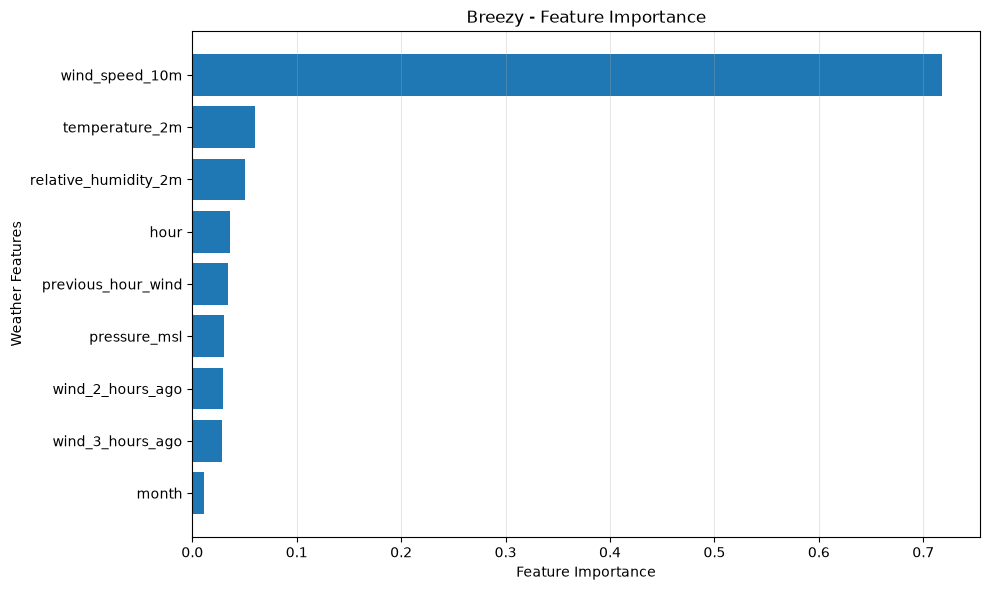

In [49]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Weather Features")
plt.title("Breezy - Feature Importance")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig("../data/feature_importance.png", dpi=300)

plt.show()

In [50]:
predictions = model.predict(X_test)

print("Predictions generated successfully!")
print("Number of predictions:", len(predictions))

Predictions generated successfully!
Number of predictions: 883


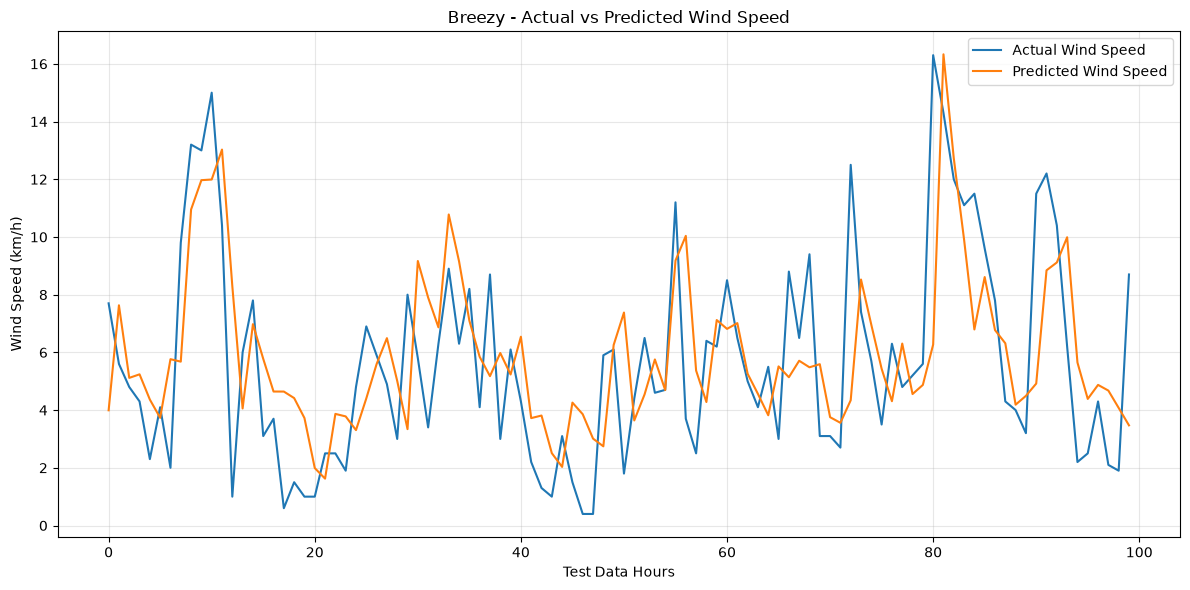

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    y_test.iloc[:100].values,
    label="Actual Wind Speed"
)

plt.plot(
    predictions[:100],
    label="Predicted Wind Speed"
)

plt.xlabel("Test Data Hours")
plt.ylabel("Wind Speed (km/h)")
plt.title("Breezy - Actual vs Predicted Wind Speed")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../data/prediction_comparison.png", dpi=300)

plt.show()

In [52]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Model performance
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

# Baseline performance
baseline_predictions = X_test["wind_speed_10m"]
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

print("BREEZY MODEL PERFORMANCE")
print("-------------------------")
print("Model MAE:", round(mae, 2), "km/h")
print("Model RMSE:", round(rmse, 2), "km/h")
print("Baseline MAE:", round(baseline_mae, 2), "km/h")

BREEZY MODEL PERFORMANCE
-------------------------
Model MAE: 2.1 km/h
Model RMSE: 2.72 km/h
Baseline MAE: 2.38 km/h


## Wind Direction Prediction

In [53]:
# Convert next-hour wind direction into radians
direction_radians = np.deg2rad(
    df["wind_direction_10m"].shift(-1)
)

# Convert direction into sine and cosine
df["target_direction_sin"] = np.sin(direction_radians)
df["target_direction_cos"] = np.cos(direction_radians)

# Remove the final row where next-hour direction is unavailable
df = df.dropna(
    subset=["target_direction_sin", "target_direction_cos"]
)

# Display the prepared data
df[[
    "wind_direction_10m",
    "target_direction_sin",
    "target_direction_cos"
]].head()

,wind_direction_10m,target_direction_sin,target_direction_cos
3,346,-0.224951,0.974370
4,347,-0.390731,0.920505
5,337,0.573576,0.819152
6,35,0.809017,-0.587785
7,126,0.275637,-0.961262


In [54]:
direction_features = [
    "temperature_2m",
    "relative_humidity_2m",
    "pressure_msl",
    "hour",
    "month",
    "wind_speed_10m",
    "previous_hour_wind",
    "wind_2_hours_ago",
    "wind_3_hours_ago",
    "wind_direction_10m"
]

X_direction = df[direction_features]

y_direction = df[
    ["target_direction_sin", "target_direction_cos"]
]

print("Features shape:", X_direction.shape)
print("Target shape:", y_direction.shape)

Features shape: (4411, 10)
Target shape: (4411, 2)


In [55]:
split_index = int(len(X_direction) * 0.8)

X_direction_train = X_direction.iloc[:split_index]
X_direction_test = X_direction.iloc[split_index:]

y_direction_train = y_direction.iloc[:split_index]
y_direction_test = y_direction.iloc[split_index:]

print("Training data:", X_direction_train.shape)
print("Testing data:", X_direction_test.shape)

Training data: (3528, 10)
Testing data: (883, 10)


In [56]:
from sklearn.ensemble import RandomForestRegressor

direction_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

direction_model.fit(
    X_direction_train,
    y_direction_train
)

print("Wind direction model trained successfully!")

Wind direction model trained successfully!


In [57]:
direction_predictions = direction_model.predict(X_direction_test)

print("First 10 predictions:")
print(direction_predictions[:10])

First 10 predictions:
[[-0.14761226  0.2436099 ]
 [-0.18384567  0.18707902]
 [ 0.01789144  0.42821924]
 [ 0.10191686  0.54472987]
 [ 0.44137933  0.56855048]
 [ 0.41702408  0.21349083]
 [-0.41602296  0.17298071]
 [-0.91097111  0.34690443]
 [-0.59619051  0.28437164]
 [-0.97068952  0.09950086]]


In [58]:
# Extract predicted sine and cosine
predicted_sin = direction_predictions[:, 0]
predicted_cos = direction_predictions[:, 1]

# Convert predictions into degrees
predicted_directions = np.degrees(
    np.arctan2(predicted_sin, predicted_cos)
)

# Keep directions between 0 and 360
predicted_directions = predicted_directions % 360

print("First 10 predicted wind directions:")
print(predicted_directions[:10])

First 10 predicted wind directions:
[328.78677576 315.49943392   2.39248484  10.597301    37.82304451
  62.89032967 292.57734905 290.84719773 295.50026297 275.85268173]


In [59]:
actual_sin = y_direction_test["target_direction_sin"].values
actual_cos = y_direction_test["target_direction_cos"].values

actual_directions = np.degrees(
    np.arctan2(actual_sin, actual_cos)
)

actual_directions = actual_directions % 360

print("First 10 actual wind directions:")
print(actual_directions[:10])

First 10 actual wind directions:
[290. 360. 354.  48.  85.  45. 315.   5. 287. 274.]


In [60]:
# Calculate the smallest angular difference
angle_difference = np.abs(
    predicted_directions - actual_directions
)

angular_errors = np.minimum(
    angle_difference,
    360 - angle_difference
)

# Calculate mean angular error
mean_angular_error = np.mean(angular_errors)

print("Mean Angular Error:", round(mean_angular_error, 2), "degrees")

Mean Angular Error: 29.61 degrees


In [61]:
baseline_directions = (
    X_direction_test["wind_direction_10m"].values
)

baseline_difference = np.abs(
    baseline_directions - actual_directions
)

baseline_errors = np.minimum(
    baseline_difference,
    360 - baseline_difference
)

baseline_mae = np.mean(baseline_errors)

print(
    "Baseline Mean Angular Error:",
    round(baseline_mae, 2),
    "degrees"
)

print(
    "Random Forest Mean Angular Error:",
    round(mean_angular_error, 2),
    "degrees"
)

Baseline Mean Angular Error: 28.81 degrees
Random Forest Mean Angular Error: 29.61 degrees


In [62]:
# Convert current wind direction into radians
current_direction_radians = np.deg2rad(
    df["wind_direction_10m"]
)

# Create circular direction features
df["wind_direction_sin"] = np.sin(
    current_direction_radians
)

df["wind_direction_cos"] = np.cos(
    current_direction_radians
)

print(
    df[[
        "wind_direction_10m",
        "wind_direction_sin",
        "wind_direction_cos"
    ]].head()
)

   wind_direction_10m  wind_direction_sin  wind_direction_cos
3                 346           -0.241922            0.970296
4                 347           -0.224951            0.974370
5                 337           -0.390731            0.920505
6                  35            0.573576            0.819152
7                 126            0.809017           -0.587785


In [63]:
direction_features = [
    "temperature_2m",
    "relative_humidity_2m",
    "pressure_msl",
    "hour",
    "month",
    "wind_speed_10m",
    "previous_hour_wind",
    "wind_2_hours_ago",
    "wind_3_hours_ago",
    "wind_direction_sin",
    "wind_direction_cos"
]

X_direction = df[direction_features]

y_direction = df[
    ["target_direction_sin", "target_direction_cos"]
]

print("Features shape:", X_direction.shape)
print("Target shape:", y_direction.shape)


Features shape: (4411, 11)
Target shape: (4411, 2)


In [64]:
split_index = int(len(X_direction) * 0.8)

X_direction_train = X_direction.iloc[:split_index]
X_direction_test = X_direction.iloc[split_index:]

y_direction_train = y_direction.iloc[:split_index]
y_direction_test = y_direction.iloc[split_index:]

print("Training:", X_direction_train.shape)
print("Testing:", X_direction_test.shape)

Training: (3528, 11)
Testing: (883, 11)


In [65]:
direction_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

direction_model.fit(
    X_direction_train,
    y_direction_train
)

print("Improved wind direction model trained!")

Improved wind direction model trained!


In [66]:
direction_predictions = direction_model.predict(X_direction_test)

predicted_sin = direction_predictions[:, 0]
predicted_cos = direction_predictions[:, 1]

predicted_directions = np.degrees(
    np.arctan2(predicted_sin, predicted_cos)
) % 360

print("First 10 improved predictions:")
print(np.round(predicted_directions[:10], 2))

First 10 improved predictions:
[333.11 317.88  32.27  17.19  32.42  57.76 294.27 293.04 300.51 276.42]


In [67]:
angle_difference = np.abs(
    predicted_directions - actual_directions
)

angular_errors = np.minimum(
    angle_difference,
    360 - angle_difference
)

improved_angular_error = np.mean(angular_errors)

print(
    "Improved Mean Angular Error:",
    round(improved_angular_error, 2),
    "degrees"
)

print(
    "Baseline Mean Angular Error:",
    round(baseline_mae, 2),
    "degrees"
)

Improved Mean Angular Error: 29.77 degrees
Baseline Mean Angular Error: 28.81 degrees


In [68]:
# Calculate how much wind direction changes each hour
current_direction = df["wind_direction_10m"].values

next_direction = np.roll(current_direction, -1)

difference = np.abs(next_direction - current_direction)

hourly_direction_change = np.minimum(
    difference,
    360 - difference
)

print(
    "Average hourly direction change:",
    round(np.mean(hourly_direction_change), 2),
    "degrees"
)

print(
    "Maximum hourly direction change:",
    round(np.max(hourly_direction_change), 2),
    "degrees"
)

Average hourly direction change: 30.38 degrees
Maximum hourly direction change: 180 degrees


In [69]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    {"model": model, "features": features},
    "../models/wind_speed_model.pkl"
)

print("Wind speed model saved successfully!")

Wind speed model saved successfully!


In [70]:
evaluation["Difference"] = (
    evaluation["Predicted"] - evaluation["Actual"]
)

evaluation["Difference"].mean()

np.float64(-0.4394915062287656)

In [71]:
evaluation["Wind Category"] = pd.cut(
    evaluation["Actual"],
    bins=[-1, 5, 10, 15, 20, float("inf")],
    labels=["0–5", "5–10", "10–15", "15–20", "Above 20"]
)

category_errors = evaluation.groupby(
    "Wind Category",
    observed=False
).agg(
    Count=("Error", "count"),
    Average_Error=("Error", "mean")
)

category_errors.round(2)

,Count,Average_Error
Wind Category,,
0–5,270,1.88
5–10,358,1.84
10–15,193,2.64
15–20,60,2.90
Above 20,2,0.70


<Axes: title={'center': 'Prediction Error by Wind Speed Category'}, xlabel='Actual Wind Speed (km/h)', ylabel='Average Error (km/h)'>

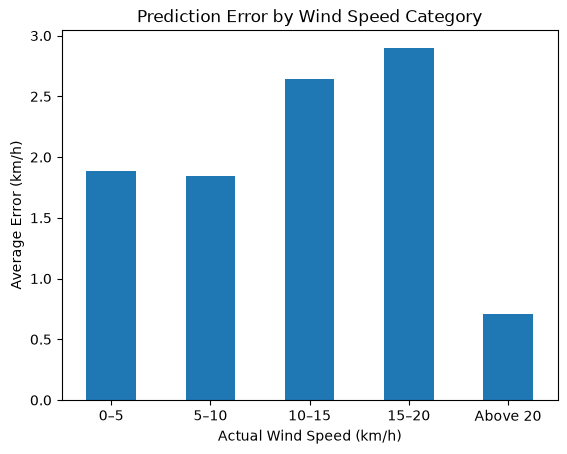

In [72]:
category_errors["Average_Error"].plot(
    kind="bar",
    title="Prediction Error by Wind Speed Category",
    ylabel="Average Error (km/h)",
    xlabel="Actual Wind Speed (km/h)",
    rot=0
)

In [73]:
evaluation["Actual Change"] = (
    y_test.values - X_test["wind_speed_10m"].values
)

evaluation[["Actual", "Predicted", "Error", "Actual Change"]].head(10)

,Actual,Predicted,Error,Actual Change
0,7.7,3.993,3.707,5.6
1,5.6,7.632,2.032,-2.1
2,4.8,5.116,0.316,-0.8
3,4.3,5.239,0.939,-0.5
4,2.3,4.365,2.065,-2.0
5,4.1,3.731,0.369,1.8
6,2.0,5.764,3.764,-2.1
7,9.8,5.679,4.121,7.8
8,13.2,10.952,2.248,3.4
9,13.0,11.968,1.032,-0.2


In [74]:
evaluation["Change Category"] = pd.cut(
    evaluation["Actual Change"],
    bins=[-float("inf"), -5, -2, 2, 5, float("inf")],
    labels=[
        "Sharp decrease",
        "Moderate decrease",
        "Stable",
        "Moderate increase",
        "Sharp increase"
    ]
)

change_errors = evaluation.groupby(
    "Change Category",
    observed=False
).agg(
    Count=("Error", "count"),
    Average_Error=("Error", "mean")
)

change_errors.round(2)

,Count,Average_Error
Change Category,,
Sharp decrease,43,3.71
Moderate decrease,178,2.04
Stable,463,1.29
Moderate increase,149,2.96
Sharp increase,50,5.81


<Axes: title={'center': 'Prediction Error by Wind Speed Change'}, xlabel='Wind Speed Change', ylabel='Average Error (km/h)'>

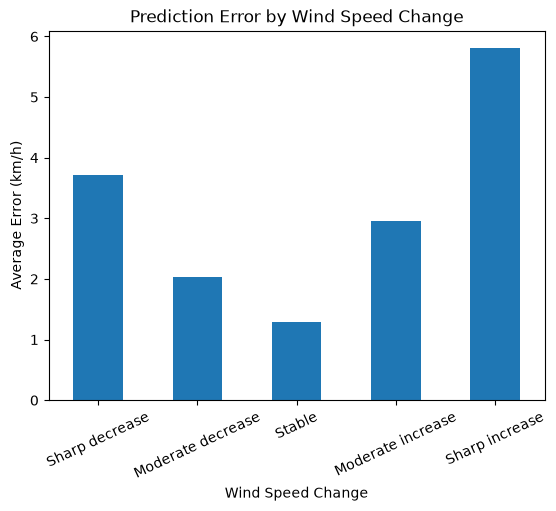

In [75]:
change_errors["Average_Error"].plot(
    kind="bar",
    title="Prediction Error by Wind Speed Change",
    ylabel="Average Error (km/h)",
    xlabel="Wind Speed Change",
    rot=25
)